# DBSCAN - Density-Based Spatial Clustering of Applications with Noise

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

In [67]:
X, y = make_moons()

In [68]:
X.shape, y.shape

((100, 2), (100,))

In [69]:
moon_data = pd.DataFrame(X, columns=["f1", "f2"])
moon_data["class"] = y
moon_data.sample(5)

,f1,f2,class
29,0.073083,0.124733,1
54,0.777479,-0.474928,1
32,1.222521,-0.474928,1
40,0.537462,-0.386599,1
43,-0.159600,0.987182,0


In [70]:
X = moon_data.drop(labels=["class"], axis=1)
X.sample(5)

,f1,f2
4,-0.967295,0.253655
94,0.404783,0.914413
22,0.427883,-0.320172
57,0.801414,0.598111
9,-0.518393,0.855143


In [71]:
dbs_cluster = DBSCAN(eps=0.2, min_samples=2)

In [72]:
class_prob = dbs_cluster.fit_predict(X)

In [73]:
moon_data["class_prob"] = class_prob

In [74]:
print("Cluster labels:", set(class_prob))
print(moon_data["class_prob"].value_counts())
print(moon_data["class"].value_counts())

Cluster labels: {np.int64(0), np.int64(1)}
class_prob
0    50
1    50
Name: count, dtype: int64
class
0    50
1    50
Name: count, dtype: int64


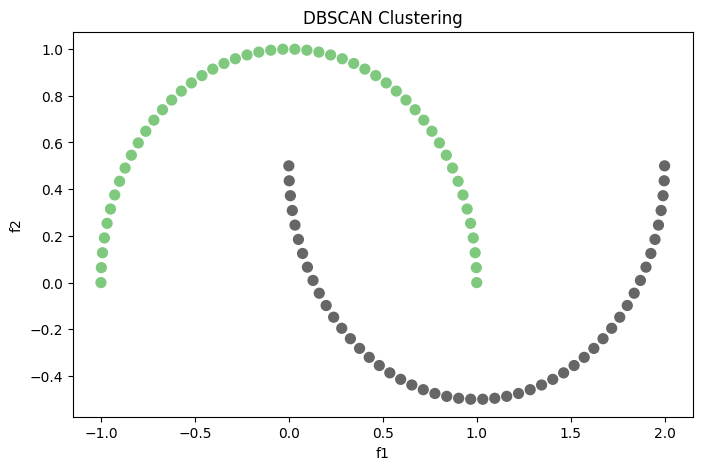

In [76]:
plt.figure(figsize=(8, 5))

plt.scatter(
    moon_data["f1"],
    moon_data["f2"],
    c=moon_data["class_prob"],
    cmap="Accent",
    s=50
)

plt.xlabel("f1")
plt.ylabel("f2")
plt.title("DBSCAN Clustering")
plt.show()


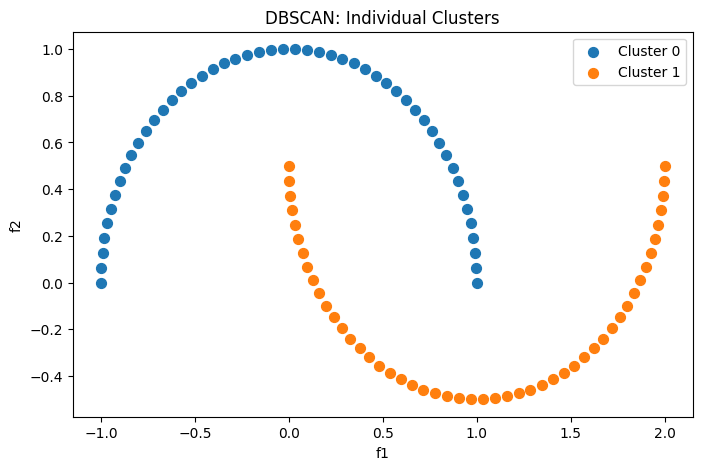

In [79]:
# Visualize individual clusters
plt.figure(figsize=(8, 5))

for cluster in sorted(moon_data["class_prob"].unique()):
    cluster_data = moon_data[moon_data["class_prob"] == cluster]

    plt.scatter(
        cluster_data["f1"],
        cluster_data["f2"],
        label="Noise (-1)" if cluster == -1 else f"Cluster {cluster}",
        s=50
    )

plt.xlabel("f1")
plt.ylabel("f2")
plt.title("DBSCAN: Individual Clusters")
plt.legend()
plt.show()